# Part E: Sensitivity Analysis

This notebook examines whether the car-dependency results are sensitive to the selected travel-time threshold. Results are compared across 15, 30 and 45-minute accessibility scenarios to determine whether the overall conclusions and spatial patterns remain consistent.

In [1]:
# Import libraries

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Sensitivity analysis environment is working.")

Sensitivity analysis environment is working.


In [2]:
# Set project paths

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

analysis_ready = (
    project_root / "data" / "processed" / "analysis_ready"
)

print("Analysis-ready folder exists:", analysis_ready.exists())

Analysis-ready folder exists: True


In [3]:
# Load accessibility and CDI results

cdi_all = pd.read_csv(
    analysis_ready / "accessibility_cdi_by_threshold.csv",
    dtype={"from_id": str}
)

print("Records:", len(cdi_all))
print("Thresholds:", sorted(cdi_all["threshold_min"].unique()))

display(cdi_all.head())

Records: 168
Thresholds: [np.int64(15), np.int64(30), np.int64(45)]


,from_id,threshold_min,car_access,pt_access,access_gap,CDI
0,60401107501,15,1.0,0.208929,0.791071,0.654357
1,60401107502,15,1.0,0.098214,0.901786,0.821138
2,60401107503,15,1.0,0.098214,0.901786,0.821138
3,60401107504,15,1.0,0.183929,0.816071,0.689291
4,60401107505,15,1.0,0.096429,0.903571,0.824104


In [4]:
# Summarise CDI across the three travel-time thresholds

sensitivity_summary = (
    cdi_all
    .groupby("threshold_min")["CDI"]
    .agg(
        defined="count",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max"
    )
    .reset_index()
)

sensitivity_summary["undefined"] = (
    56 - sensitivity_summary["defined"]
)

display(sensitivity_summary)

,threshold_min,defined,mean,median,minimum,maximum,undefined
0,15,54,0.894271,0.951220,0.542700,1.0,2
1,30,55,0.629863,0.635036,0.149897,1.0,1
2,45,56,0.344328,0.181435,0.025641,1.0,0


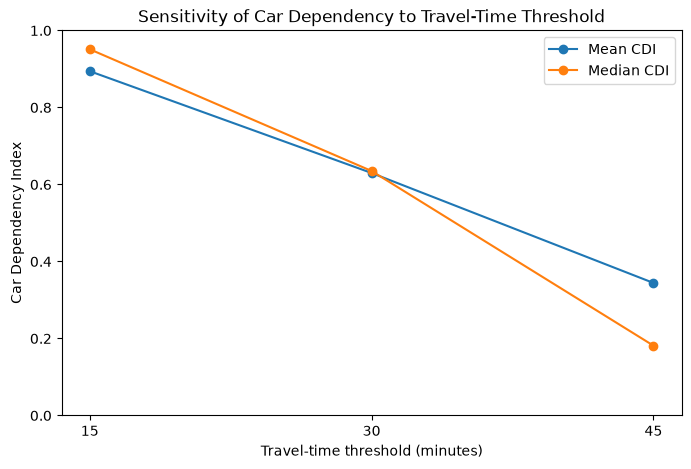

In [5]:
# Plot mean and median CDI by travel-time threshold

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    sensitivity_summary["threshold_min"],
    sensitivity_summary["mean"],
    marker="o",
    label="Mean CDI"
)

ax.plot(
    sensitivity_summary["threshold_min"],
    sensitivity_summary["median"],
    marker="o",
    label="Median CDI"
)

ax.set_xlabel("Travel-time threshold (minutes)")
ax.set_ylabel("Car Dependency Index")
ax.set_title("Sensitivity of Car Dependency to Travel-Time Threshold")
ax.set_xticks([15, 30, 45])
ax.set_ylim(0, 1)
ax.legend()

plt.show()

## E3. Stability of Spatial Car-Dependency Patterns

The relative ranking of SA1 car dependency is compared across the 15, 30 and 45-minute thresholds. Spearman rank correlations are used to determine whether SA1s that are relatively more car-dependent under one threshold also tend to remain more car-dependent under alternative travel-time assumptions.

In [6]:
# Reshape CDI results so each threshold is a separate column

cdi_wide = cdi_all.pivot(
    index="from_id",
    columns="threshold_min",
    values="CDI"
)

cdi_wide = cdi_wide.rename(
    columns={
        15: "CDI_15",
        30: "CDI_30",
        45: "CDI_45"
    }
)

display(cdi_wide.head())

threshold_min,CDI_15,CDI_30,CDI_45
from_id,,,
60401107501,0.654357,0.244444,0.157025
60401107502,0.821138,0.191489,0.133603
60401107503,0.821138,0.338112,0.157025
60401107504,0.689291,0.264108,0.087379
60401107505,0.824104,0.447028,0.140530


In [7]:
# Compare SA1 CDI rankings across thresholds

rank_correlations = cdi_wide.corr(
    method="spearman"
)

display(rank_correlations)

threshold_min,CDI_15,CDI_30,CDI_45
threshold_min,,,
CDI_15,1.000000,0.739793,0.704590
CDI_30,0.739793,1.000000,0.798219
CDI_45,0.704590,0.798219,1.000000


## E4. Sensitivity Analysis Summary

Car dependency decreased as the travel-time threshold increased, with mean CDI declining from approximately 0.89 at 15 minutes to 0.63 at 30 minutes and 0.34 at 45 minutes. This indicates that public-transport accessibility improves when longer travel times are allowed.

However, the relative spatial pattern remained reasonably stable. Spearman rank correlations between SA1 CDI values ranged from approximately 0.70 to 0.80 across the three thresholds. Therefore, although the magnitude of car dependency is sensitive to the selected travel-time threshold, SA1s that are relatively more car-dependent generally remain so under alternative threshold assumptions.

In [9]:
# Save sensitivity-analysis results

sensitivity_summary.to_csv(
    analysis_ready / "cdi_sensitivity_summary.csv",
    index=False
)

rank_correlations.to_csv(
    analysis_ready / "cdi_rank_correlations.csv"
)

print("Sensitivity results saved.")

Sensitivity results saved.


# Part E2: Final Six-Category Sensitivity Analysis

The sensitivity analysis is repeated using the final six-category accessibility framework. Car Dependency Index values are compared across 15, 30 and 45-minute travel-time thresholds to assess whether the magnitude and spatial pattern of car dependency remain consistent under alternative accessibility assumptions.

In [10]:
# Load the final six-category CDI results

cdi_final = pd.read_csv(
    analysis_ready / "accessibility_cdi_6categories_by_threshold.csv",
    dtype={"from_id": str}
)

print("Records:", len(cdi_final))
print("Thresholds:", sorted(cdi_final["threshold_min"].unique()))

print("\nDefined CDI values by threshold:")
print(
    cdi_final
    .groupby("threshold_min")["CDI"]
    .count()
)

Records: 168
Thresholds: [np.int64(15), np.int64(30), np.int64(45)]

Defined CDI values by threshold:
threshold_min
15    55
30    56
45    56
Name: CDI, dtype: int64


In [11]:
# Summarise final CDI across travel-time thresholds

sensitivity_summary_final = (
    cdi_final
    .groupby("threshold_min")["CDI"]
    .agg(
        defined="count",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max"
    )
    .reset_index()
)

sensitivity_summary_final["undefined"] = (
    56 - sensitivity_summary_final["defined"]
)

display(sensitivity_summary_final)

,threshold_min,defined,mean,median,minimum,maximum,undefined
0,15,55,0.901236,0.922419,0.612104,1.0,1
1,30,56,0.667200,0.665904,0.226966,1.0,0
2,45,56,0.393262,0.250825,0.066302,1.0,0


## E5. Stability of Final Car-Dependency Patterns

The relative ranking of Burnie SA1s is compared across the 15, 30 and 45-minute scenarios using Spearman rank correlation. This tests whether areas that are relatively more car-dependent remain comparatively car-dependent when the travel-time threshold changes.

In [12]:
# Reshape final CDI results by threshold

cdi_final_wide = cdi_final.pivot(
    index="from_id",
    columns="threshold_min",
    values="CDI"
)

cdi_final_wide = cdi_final_wide.rename(
    columns={
        15: "CDI_15",
        30: "CDI_30",
        45: "CDI_45"
    }
)

display(cdi_final_wide.head())

threshold_min,CDI_15,CDI_30,CDI_45
from_id,,,
60401107501,0.745542,0.361992,0.169248
60401107502,0.860957,0.299974,0.153196
60401107503,0.860230,0.424596,0.175268
60401107504,0.720464,0.342265,0.120881
60401107505,0.862317,0.527095,0.167644


In [13]:
# Calculate Spearman rank correlations between thresholds

rank_correlations_final = cdi_final_wide.corr(
    method="spearman"
)

display(rank_correlations_final)

threshold_min,CDI_15,CDI_30,CDI_45
threshold_min,,,
CDI_15,1.000000,0.798070,0.823378
CDI_30,0.798070,1.000000,0.892899
CDI_45,0.823378,0.892899,1.000000


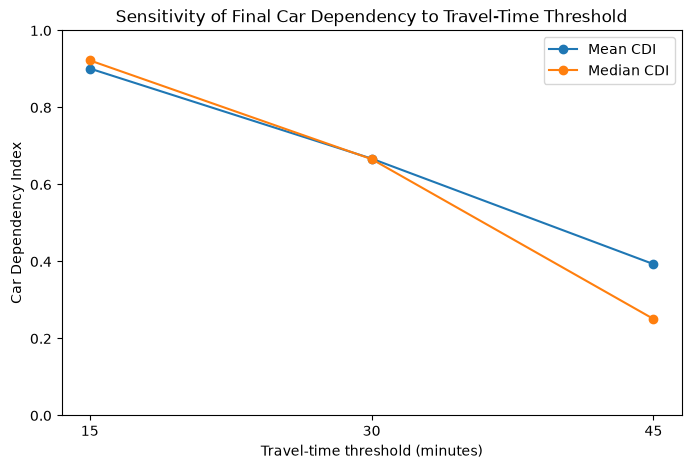

In [14]:
# Plot final mean and median CDI by threshold

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    sensitivity_summary_final["threshold_min"],
    sensitivity_summary_final["mean"],
    marker="o",
    label="Mean CDI"
)

ax.plot(
    sensitivity_summary_final["threshold_min"],
    sensitivity_summary_final["median"],
    marker="o",
    label="Median CDI"
)

ax.set_xlabel("Travel-time threshold (minutes)")
ax.set_ylabel("Car Dependency Index")
ax.set_title(
    "Sensitivity of Final Car Dependency to Travel-Time Threshold"
)

ax.set_xticks([15, 30, 45])
ax.set_ylim(0, 1)
ax.legend()

plt.show()

In [15]:
# Save final six-category sensitivity outputs

sensitivity_summary_final.to_csv(
    analysis_ready / "cdi_sensitivity_6categories.csv",
    index=False
)

rank_correlations_final.to_csv(
    analysis_ready / "cdi_rank_correlations_6categories.csv"
)

print("Final six-category sensitivity results saved.")

Final six-category sensitivity results saved.
